# 10h → 2h multi-group modelling — resource-aware workflow

A lightweight companion to the existing `modeling_10h2h_*` notebooks. It preserves the important evaluation design—unseen sources and a held-out 2h capture—while avoiding duplicate dataframes, leakage-prone shuffled splits, multiple model families, and learning-curve/permutation-importance runs during iteration.

Use this notebook to select feature sets and a reasonable data cap. Run the original full workflow only once for final, thesis-reportable results.

In [1]:
from pathlib import Path
import gc
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import GroupShuffleSplit
import matplotlib.pyplot as plt

# Select one of the four experiments.  Paths are relative to code/modeling/.
EXPERIMENT = 'sa54_same'  # sa54_same, sa54_diff, ip12_same, ip12_diff
CONFIGS = {
    'sa54_same': {
        'folder': '../../data/2Groups_3Devices_10h_Seewis_SamsungA54BudsFEAirtags_SameDistances',
        'eval': '2Groups_3Devices_2h_Uni_SamsungA54BudsFEAirtags_SameDistances_labeled.csv',
    },
    'sa54_diff': {
        'folder': '../../data/2Groups_3Devices_10h_apartment',
        'eval': '2Groups_3Devices_2h_uni_labeled.csv',
    },
    'ip12_same': {
        'folder': '../../data/2Groups_3Devices_10h_Seewis_IphoneAirpodsSamsungTag_SameDistances',
        'eval': '2Groups_3Devices_2h_Uni_IphoneAirpodsSamsungTag_SameDistances_labeled.csv',
    },
    'ip12_diff': {
        'folder': '../../data/2Groups_3Devices_10h_Seewis_IphoneAirpodsSamsungTag_DiffDistances',
        'eval': '2Groups_3Devices_2h_Uni_IphoneAirpodsSamsungTag_DiffDistances_labeled.csv',
    },
}

# Start at 100k per class (at most 300k rows for 0/G1/G2).
# Use None only for the final full-data run.
MAX_TRAIN_PACKETS_PER_CLASS = 100_000
MAX_EVAL_PACKETS_PER_CLASS = 100_000
RANDOM_STATE = 1
WINDOW_SECONDS = 0.5

# Ablation switches -----------------------------------------------------
# USE_PAYLOAD_FEATURES adds per-source payload-signature features (modal hash,
# modal share, unique count, modal length) for `data` and `service_data`.
USE_PAYLOAD_FEATURES = True
# SOURCE_LEVEL_EVAL also scores one decision per source (majority vote).
SOURCE_LEVEL_EVAL = True

cfg = CONFIGS[EXPERIMENT]
base = Path(cfg['folder'])
# Folder names are not perfectly uniform, so discover the five training blocks instead.
train_files = sorted(base.glob('*Hours*To*_labeled.csv'))
eval_file = base / cfg['eval']
print(f'Experiment: {EXPERIMENT}; {len(train_files)} training blocks; evaluation: {eval_file.name}')


Experiment: sa54_same; 5 training blocks; evaluation: 2Groups_3Devices_2h_Uni_SamsungA54BudsFEAirtags_SameDistances_labeled.csv


In [2]:
import hashlib

def _hash64(text: str) -> int:
    """Stable 24-bit hash: exact in float32, negligible collisions at payload cardinality."""
    return int.from_bytes(hashlib.blake2b(text.encode("utf-8"), digest_size=4).digest(), "big") & 0xFFFFFF

PAYLOAD_TAIL_BYTES = 6   # trailing bytes kept per payload column
_HEX_BYTE = {f"{i:02x}": i for i in range(256)}
_HEX_BYTE.update({f"{i:02X}": i for i in range(256)})

def _payload_stats(df: pd.DataFrame, column: str):
    """Per-source payload signature: how stable the payload is, and its trailing bytes.

    Stability (modal share, number of distinct values, modal length) separates a payload
    that is constant per unit from one that rotates.

    The trailing bytes carry the per-unit constant for some vendors (Samsung Buds FE:
    ...0000ab00 vs ...00000700, stable over 10 h and across a separate capture).  A hash
    of the *whole* payload would not transfer: Samsung also rotates byte 10 once per
    session (1c -> 1d, 03 -> 08), so the hash changes between captures while the tail
    does not.  Trailing bytes are used because the suffix is where manufacturers tend to
    put a unit-specific value, and because a byte value (0-255) is a single clean split
    for a tree, unlike a 24-bit hash.
    """
    if column not in df.columns:
        return None
    x = df[["_src", column]].copy()
    x[column] = x[column].fillna("").astype(str)
    g = x.groupby(["_src", column], observed=True).size().rename("cnt").reset_index()
    g["tot"] = g.groupby("_src", observed=True)["cnt"].transform("sum")
    g = g.sort_values(["_src", "cnt"], ascending=[True, False])
    top = g.drop_duplicates("_src")[["_src", column, "cnt", "tot"]].copy()
    uniq = g.groupby("_src", observed=True).size()
    top[f"{column}_modal_share"] = (top["cnt"] / top["tot"]).astype("float32")
    top[f"{column}_nuniq"] = top["_src"].map(uniq).astype("int32")
    top[f"{column}_modal_len"] = top[column].str.len().astype("int16")

    # "~" pads short payloads so that byte j always means "j-th byte from the end".
    tail = top[column].str.slice(-2 * PAYLOAD_TAIL_BYTES).str.rjust(2 * PAYLOAD_TAIL_BYTES, "~")
    for j in range(PAYLOAD_TAIL_BYTES):
        chunk = tail.str.slice(2 * j, 2 * j + 2)
        top[f"{column}_tail{j}"] = chunk.map(_HEX_BYTE).fillna(-1).astype("int16")
    return top.drop(columns=[column, "cnt", "tot"])

def add_compact_features(df: pd.DataFrame, window_seconds: float = WINDOW_SECONDS) -> pd.DataFrame:
    """Build compact numeric features without retaining raw payload columns afterwards."""
    df = df.copy()
    df["time"] = pd.to_numeric(df["time"], errors="coerce").fillna(0).astype("float32")
    df["_src"] = df["source"].astype(str)
    df["source"] = df["source"].astype("category")

    for column in ("info", "channel"):
        if column in df:
            encoded = pd.get_dummies(df[column], prefix="is", dtype=np.uint8)
            df = pd.concat([df.drop(columns=column), encoded], axis=1)

    # Presence/length fields are deliberately device-agnostic; raw payload strings are discarded.
    for column in ("company_id", "uuid16", "uuid128", "data", "ad_type", "service_data"):
        if column in df:
            df[f"has_{column}"] = df[column].notna().astype(np.uint8)
            if column in ("data", "ad_type", "service_data"):
                df[f"{column}_length"] = df[column].fillna("").astype(str).str.len().astype("int16")

    # --- payload signature (per source) ---------------------------------------------
    # Two identical units usually share every length/type/timing statistic but can still
    # carry a per-unit constant inside the manufacturer/service payload. These features
    # make that constant available to the model (and expose when it rotates instead).
    if USE_PAYLOAD_FEATURES:
        for column in ("data", "service_data"):
            stats = _payload_stats(df, column)
            if stats is not None:
                df = df.merge(stats, on="_src", how="left")
    # --------------------------------------------------------------------------------

    # Source-local cadence: source is kept only for grouped splitting, never supplied to the model.
    df = df.sort_values(["source", "time"])
    iat = df.groupby("source", observed=True)["time"].diff()
    df["iat"] = iat.fillna(0).astype("float32")
    source_iat = df.groupby("source", observed=True)["iat"].agg(["median", "mean", "std"]).fillna(0)
    source_iat.columns = ["iat_median", "iat_mean", "iat_std"]
    df = df.join(source_iat, on="source")

    # Capture-local co-activity; no group labels or device labels are involved.
    bins = np.floor(df["time"] / window_seconds).astype("int64")
    df["_time_bin"] = bins
    bin_stats = df.groupby("_time_bin", observed=True).agg(
        bin_total_packets=("source", "size"), bin_distinct_sources=("source", "nunique")
    )
    df = df.join(bin_stats, on="_time_bin")
    df["coactive_packets"] = (df["bin_total_packets"] - 1).astype("int16")
    df["coactive_sources"] = (df["bin_distinct_sources"] - 1).astype("int16")
    df["coactive_density"] = (df["coactive_packets"] / df["bin_total_packets"].clip(lower=1)).astype("float32")

    keep = [
        "source", "time", "group_label_multi", "group_label", "group_id", "labelled_device",
        "iat", "iat_median", "iat_mean", "iat_std", "bin_total_packets",
        "bin_distinct_sources", "coactive_packets", "coactive_sources", "coactive_density",
    ]
    keep += [c for c in df.columns if c.startswith("is_") or c.startswith("has_") or c.endswith("_length")]
    if USE_PAYLOAD_FEATURES:
        payload_suffixes = ("_modal_share", "_nuniq", "_modal_len") + tuple(
            f"_tail{j}" for j in range(PAYLOAD_TAIL_BYTES))
        keep += [c for c in df.columns if c.endswith(payload_suffixes)]
    keep = [c for c in keep if c in df.columns]
    return df[keep].copy()

def cap_per_class(df: pd.DataFrame, label_col: str, max_rows=None) -> pd.DataFrame:
    if max_rows is None:
        return df
    return (df.groupby(label_col, group_keys=False, observed=True)
              .apply(lambda group: group.sample(n=min(len(group), max_rows), random_state=RANDOM_STATE))
              .reset_index(drop=True))


In [3]:
# Process one file at a time, retaining only its compact numeric representation.
train_parts = []
for path in train_files:
    raw = pd.read_csv(path, low_memory=False)
    compact = add_compact_features(raw)
    train_parts.append(compact)
    print(f'{path.name}: raw={len(raw):,}, compact={len(compact):,}')
    del raw, compact
    gc.collect()

train_df = pd.concat(train_parts, ignore_index=True)
del train_parts
gc.collect()
train_df['source'] = train_df['source'].astype('category')

raw_eval = pd.read_csv(eval_file, low_memory=False)
eval_df_full = add_compact_features(raw_eval)
del raw_eval
gc.collect()
eval_df_full['source'] = eval_df_full['source'].astype('category')
eval_df = eval_df_full

LABEL_COL = 'group_label_multi' if 'group_label_multi' in train_df.columns else 'group_label'
train_df = cap_per_class(train_df, LABEL_COL, MAX_TRAIN_PACKETS_PER_CLASS)
eval_df = cap_per_class(eval_df_full, LABEL_COL, MAX_EVAL_PACKETS_PER_CLASS)  # packet-level metric only
print('Train:', train_df[LABEL_COL].value_counts().sort_index().to_dict())
print('Eval: ', eval_df[LABEL_COL].value_counts().sort_index().to_dict())
print(f'Train memory: {train_df.memory_usage(deep=True).sum() / 2**20:.1f} MiB')


2Groups_3Devices_10h_Seewis_SamsungA54BudsFEAirtags_SameDistances_Hours0To2_labeled.csv: raw=1,160,791, compact=1,160,791


2Groups_3Devices_10h_Seewis_SamsungA54BudsFEAirtags_SameDistances_Hours2To4_labeled.csv: raw=1,208,674, compact=1,208,674


2Groups_3Devices_10h_Seewis_SamsungA54BudsFEAirtags_SameDistances_Hours4To6_labeled.csv: raw=1,238,564, compact=1,238,564


2Groups_3Devices_10h_Seewis_SamsungA54BudsFEAirtags_SameDistances_Hours6To8_labeled.csv: raw=1,250,778, compact=1,250,778


2Groups_3Devices_10h_Seewis_SamsungA54BudsFEAirtags_SameDistances_Hours8To10_labeled.csv: raw=1,225,539, compact=1,225,539


C:\Users\thoma\AppData\Local\Temp\ipykernel_12160\2917215932.py:111: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda group: group.sample(n=min(len(group), max_rows), random_state=RANDOM_STATE))


Train: {0: 100000, 1: 100000, 2: 100000}
Eval:  {0: 100000, 1: 100000, 2: 59037}
Train memory: 163.2 MiB


C:\Users\thoma\AppData\Local\Temp\ipykernel_12160\2917215932.py:111: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda group: group.sample(n=min(len(group), max_rows), random_state=RANDOM_STATE))


In [4]:
# One honest split: test sources are absent from training.
non_features = {'source', 'time', 'group_label_multi', 'group_label', 'group_id', 'labelled_device'}
feature_columns = [c for c in train_df.columns if c not in non_features]
X = train_df[feature_columns].fillna(0).astype('float32')  # NaN only from blocks missing a dummy
y = train_df[LABEL_COL]
groups = train_df['source'].astype(str)

splitter = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

model = RandomForestClassifier(
    n_estimators=50, min_samples_split=10, min_samples_leaf=3,
    class_weight='balanced', random_state=RANDOM_STATE, n_jobs=2,
)
model.fit(X_train, y_train)
pred = model.predict(X_test)
print(classification_report(y_test, pred, zero_division=0))
grouped_macro_f1 = f1_score(y_test, pred, average='macro')
print(f'Grouped-split macro-F1: {grouped_macro_f1:.4f}')

# Release split matrices before the held-out-location evaluation.
del X_train, X_test, y_train, y_test, pred
gc.collect()


              precision    recall  f1-score   support

           0       1.00      1.00      1.00     29291
           1       0.59      1.00      0.74      9187
           2       0.98      0.09      0.16      6909

    accuracy                           0.86     45387
   macro avg       0.86      0.69      0.63     45387
weighted avg       0.91      0.86      0.82     45387

Grouped-split macro-F1: 0.6336


48

              precision    recall  f1-score   support

           0       0.56      0.99      0.72    100000
           1       0.49      0.33      0.39    100000
           2       0.95      0.27      0.42     59037

    accuracy                           0.57    259037
   macro avg       0.67      0.53      0.51    259037
weighted avg       0.62      0.57      0.52    259037

Held-out macro-F1 (capped eval): 0.5105



source-level (full eval): 125467 sources, 33 target (G1/G2)
  all-source accuracy: 0.999
  target-source accuracy: 0.394 (13/33)
  by device:
    AirTag      1/ 2 correct  (true1->pred1, true2->pred0)
    Buds        1/ 2 correct  (true1->pred1, true2->pred1)
    Phone      11/29 correct  (true1->pred0, true2->pred0, true2->pred2)
pred   0  1   2
true           
1     12  2   0
2      7  1  11

payload signature (eval sources):
  group 0: 125434 sources | modal share 0.928 | unique payloads 3.8 | 86% with a constant payload
  group 1:     14 sources | modal share 0.943 | unique payloads 43.1 | 93% with a constant payload
  group 2:     19 sources | modal share 0.951 | unique payloads 36.8 | 89% with a constant payload
  trailing bytes by distinct values over target sources: data_tail4=5, data_tail0=4, data_tail1=4, data_tail2=4, data_tail3=4

persistent (>=200 pkt): 1813 sources, 31 target
  G1-vs-G2 accuracy: 0.387 (12/31)
  noise leakage: 58.1% of target sources predicted noise
pred


payload signature matching (held-out source vs training roster)
  21 of 21 target sources scored | 19 without a payload match
  group match among matched sources: 100.0% (2/2)
    AirTag      0/ 2 correct |  0 matched | equal bytes [0, 1] of 6
    Buds        2/ 2 correct |  2 matched | equal bytes [6, 6] of 6
    Phone       0/17 correct |  0 matched | equal bytes [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1] of 6
match   0  1  2
true           
1       1  1  0
2      18  0  1


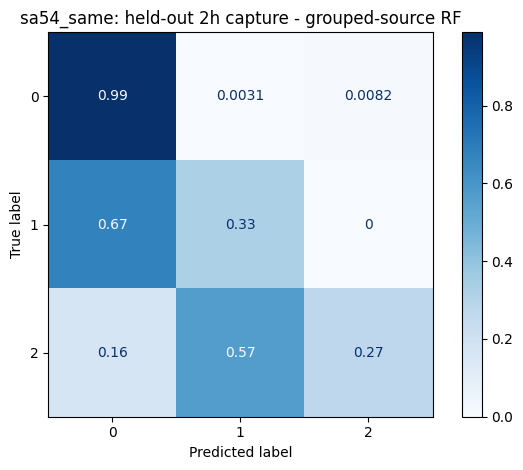

In [5]:
# --- packet-level metric (capped eval, comparable with the canonical notebooks) ------
X_eval = eval_df.reindex(columns=feature_columns).fillna(0).astype('float32')
eval_pred = model.predict(X_eval)
print(classification_report(eval_df[LABEL_COL], eval_pred, zero_division=0))
held_out_macro_f1 = f1_score(eval_df[LABEL_COL], eval_pred, average='macro')
print(f'Held-out macro-F1 (capped eval): {held_out_macro_f1:.4f}')

# --- one decision per source on the FULL eval (no packet cap) ------------------------
X_full = eval_df_full.reindex(columns=feature_columns).fillna(0).astype('float32')
pred_full = model.predict(X_full)
y_full = eval_df_full[LABEL_COL].values

def source_table(df, pred, label_col=LABEL_COL):
    tmp = pd.DataFrame({'source': df['source'].astype(str).values, 'true': y_full, 'pred': pred})
    if 'labelled_device' in df.columns:
        tmp['device'] = df['labelled_device'].astype(str).values
    else:
        tmp['device'] = '?'
    grp = tmp.groupby('source', observed=True)
    res = pd.DataFrame({
        'true': grp['true'].agg(lambda x: pd.Series(x).mode().iloc[0]),
        'pred': grp['pred'].agg(lambda x: pd.Series(x).mode().iloc[0]),
        'device': grp['device'].agg(lambda x: pd.Series(x).mode().iloc[0]),
        'packets': grp.size(),
    })
    return res

res = source_table(eval_df_full, pred_full)
tgt = res[res['true'].isin([1, 2])]
print(f'\nsource-level (full eval): {len(res)} sources, {len(tgt)} target (G1/G2)')
print(f'  all-source accuracy: {(res["true"] == res["pred"]).mean():.3f}')
if len(tgt):
    print(f'  target-source accuracy: {(tgt["true"] == tgt["pred"]).mean():.3f} ({(tgt["true"] == tgt["pred"]).sum()}/{len(tgt)})')
    print('  by device:')
    for dev, sub in tgt.groupby('device'):
        ok = (sub['true'] == sub['pred']).sum()
        print(f'    {dev:10s} {ok:2d}/{len(sub):2d} correct  ({", ".join(f"true{g}->pred{p}" for g, p in pd.crosstab(sub.true, sub.pred).stack().loc[lambda s: s > 0].index)})')
    print(pd.crosstab(tgt['true'], tgt['pred']).to_string())

# --- payload diagnostics on the full eval -------------------------------------------
tail_cols = [c for c in eval_df_full.columns if c.startswith('data_tail')]
if tail_cols:
    evs = eval_df_full.drop_duplicates('source')
    print('\npayload signature (eval sources):')
    for grp in (0, 1, 2):
        sub = evs[evs[LABEL_COL] == grp]
        if len(sub) == 0:
            continue
        constant = (sub['data_modal_share'] > 0.9).mean()
        print(f'  group {grp}: {len(sub):6d} sources | modal share {sub["data_modal_share"].mean():.3f}'
              f' | unique payloads {sub["data_nuniq"].mean():.1f}'
              f' | {constant:.0%} with a constant payload')
    # Does any trailing byte separate the target sources of the two groups?  A column with
    # 2 distinct values across the target sources is exactly the per-unit constant.
    tgt_src = evs[evs[LABEL_COL].isin([1, 2])]
    if len(tgt_src):
        sep = {c: tgt_src[c].nunique() for c in tail_cols}
        best = sorted(sep.items(), key=lambda kv: -kv[1])[:5]
        print('  trailing bytes by distinct values over target sources: '
              + ', '.join(f'{c}={v}' for c, v in best))

# --- persistent vs rotating sources --------------------------------------------------
# Only a stable MAC can be scored across sessions; rotating addresses are new sources by
# construction and cannot be identified by any per-unit constant, payload or otherwise.
PERSISTENT_MIN_PACKETS = 200
pers = res[res['packets'] >= PERSISTENT_MIN_PACKETS]
rot = res[res['packets'] < PERSISTENT_MIN_PACKETS]
for name, sub in (('persistent (>=%d pkt)' % PERSISTENT_MIN_PACKETS, pers), ('rotating', rot)):
    t = sub[sub['true'].isin([1, 2])]
    if len(t) == 0:
        continue
    print(f'\n{name}: {len(sub)} sources, {len(t)} target')
    print(f'  G1-vs-G2 accuracy: {(t["true"] == t["pred"]).mean():.3f} ({(t["true"] == t["pred"]).sum()}/{len(t)})')
    print(f'  noise leakage: {((t["pred"] == 0).mean()):.1%} of target sources predicted noise')
    print(pd.crosstab(t['true'], t['pred']).to_string())

# --- payload signature matching, model-free ----------------------------------------
# The random forest has to encode a byte value as an ordinal threshold, which cannot
# cleanly isolate "07" from "0" and "no payload".  This read-out removes the model:
# it takes the per-group reference signature from the training blocks (modal byte per
# trailing position) and reports how many held-out target sources reproduce it exactly.
def payload_signature_report(train, ev, label_col=LABEL_COL):
    """Cross-session roster lookup: match each held-out source to the TRAINING sources.

    Compares the trailing payload bytes of every held-out target source with every
    training source of both groups and assigns the group of the best match.  Only byte
    positions valid on both sides are scored, so a source without `data` is compared on
    its `service_data` bytes and vice versa.  "6/6 equal" means the per-unit constant
    survived the session change; a rotating payload gives ~1/6 and no match.
    """
    tail = [c for c in ev.columns if c.endswith(tuple(f"_tail{j}" for j in range(PAYLOAD_TAIL_BYTES)))]
    if not tail:
        print('\npayload signature matching: payload features disabled')
        return
    tr = train[train[label_col].isin([1, 2])].drop_duplicates('source')
    has_payload = (ev['data_modal_len'] > 0) | (ev['service_data_modal_len'] > 0)
    te = ev[ev[label_col].isin([1, 2]) & has_payload].drop_duplicates('source')
    if len(tr) == 0 or len(te) == 0:
        print('\npayload signature matching: not enough payload sources')
        return
    refs = {g: tr.loc[tr[label_col] == g, tail].to_numpy(dtype=float) for g in (1, 2)}
    V = te[tail].to_numpy(dtype=float)
    rows = []
    for i in range(len(te)):
        v = V[i]
        best = {}
        for g in (1, 2):
            S = refs[g]
            if S.shape[0] == 0:
                best[g] = (-1, 0)
                continue
            valid = (S >= 0) & (v >= 0)
            score = ((S == v) & valid).sum(axis=1)
            nvalid = valid.sum(axis=1)
            usable = nvalid >= 4
            if not usable.any():
                best[g] = (-1, 0)
                continue
            j = int(np.argmax(np.where(usable, score, -1)))
            best[g] = (int(score[j]), int(nvalid[j]))
        (b1, n1), (b2, n2) = best[1], best[2]
        top = max(b1, b2)
        vote = 0 if top < 4 else (1 if b1 >= b2 else 2)
        rows.append({'true': int(te[label_col].iloc[i]), 'match': vote, 'equal': top,
                     'compared': max(n1, n2),
                     'device': str(te['labelled_device'].iloc[i]) if 'labelled_device' in te else '?'})
    out = pd.DataFrame(rows)
    print('\npayload signature matching (held-out source vs training roster)')
    print(f'  {len(out)} of {te.shape[0]} target sources scored'
          f' | {int((out["match"] == 0).sum())} without a payload match')
    tgt = out[out['match'] != 0]
    if len(tgt):
        print(f'  group match among matched sources: {(tgt["true"] == tgt["match"]).mean():.1%}'
              f' ({(tgt["true"] == tgt["match"]).sum()}/{len(tgt)})')
    for dev, sub in out.groupby('device'):
        matched = sub[sub['match'] != 0]
        ok = int((matched['true'] == matched['match']).sum())
        print(f'    {dev:10s} {ok:2d}/{len(sub):2d} correct'
              f' | {len(matched):2d} matched'
              f' | equal bytes {sorted(sub["equal"].tolist())} of {sorted(sub["compared"].tolist())[-1] if len(sub) else 0}')
    print(pd.crosstab(out['true'], out['match']).to_string())

payload_signature_report(train_df, eval_df_full)

ConfusionMatrixDisplay.from_predictions(eval_df[LABEL_COL], eval_pred, normalize='true', cmap='Blues')
plt.title(f'{EXPERIMENT}: held-out 2h capture - grouped-source RF')
plt.tight_layout()
plt.show()


## Recommended execution order

Start with `MAX_*_PACKETS_PER_CLASS = 50_000`, then 100,000, then 200,000. Stop increasing it when held-out macro-F1 is effectively stable. Avoid running all four notebooks at once. For final feature importance or learning curves, make a copy of this notebook and run one selected experiment only; use `n_jobs=1` for any learning-curve computation to prevent parallel worker copies from exhausting RAM.

### Reading the ablation

Run each experiment twice: `USE_PAYLOAD_FEATURES = False` (baseline) and `True` (+payload).
Compare, per experiment:

1. **Held-out macro-F1** (packet level) — must be computed on the *uncapped* eval for final claims.
2. **G1-vs-G2 recall at source level** — the number that matters; a few sources is a few percent.
3. **`mean modal share`** — ~1.0 means the payload is constant (Samsung buds/tags), ~0.1 means it rotates (Apple).
4. **`% of eval sources with hash seen in train`** — low overlap means any gain is NOT transferable.
5. **Train/test gap** — if the grouped in-domain split jumps but the held-out capture does not, the model memorised session-specific payload bytes.

Do not compare absolute numbers across experiments unless `MAX_*_PACKETS_PER_CLASS` is identical and the eval is uncapped.


In [6]:
# --- temporary diagnostics: what did the forest actually use? ------------------------
imp = pd.Series(model.feature_importances_, index=feature_columns).sort_values(ascending=False)
print('top features:')
print(imp.head(20).to_string())

SAMSUNG_BUDS = ['dc:b9:92:eb:f6:5d', 'f0:c8:c1:88:8c:53']
tail_cols = [c for c in feature_columns if c.startswith('data_tail') or c.startswith('service_data_tail')]
show = [c for c in ['data_modal_share', 'data_nuniq', 'data_modal_len'] + tail_cols
        if c in feature_columns]
for name, frame in (('train', train_df), ('eval', eval_df_full)) if show else ():
    sub = frame[frame['source'].astype(str).isin(SAMSUNG_BUDS)]
    if len(sub) == 0:
        continue
    print(f'\n{name}: buds feature values (one row per source)')
    print(sub.groupby(sub['source'].astype(str))[show].agg('first').to_string())
    print(f'{name}: buds packet counts by source x label')
    print(pd.crosstab(sub['source'].astype(str), sub[LABEL_COL]).to_string())

mask = eval_df_full['source'].astype(str).isin(SAMSUNG_BUDS).values
print('\neval buds predictions:')
print(pd.crosstab(eval_df_full.loc[mask, 'source'].astype(str), pred_full[mask]).to_string())


top features:
data_nuniq                  0.142214
iat_mean                    0.135299
data_tail4                  0.127774
iat_std                     0.086510
data_modal_share            0.055830
data_modal_len              0.054320
iat_median                  0.050731
is_ADV_SCAN_IND             0.034280
data_tail2                  0.033913
data_length                 0.030261
data_tail5                  0.025822
data_tail1                  0.025620
data_tail3                  0.024906
data_tail0                  0.023067
service_data_length         0.022843
service_data_modal_share    0.017875
is_ADV_IND                  0.015935
service_data_tail1          0.013067
service_data_nuniq          0.010719
ad_type_length              0.009668

train: buds feature values (one row per source)
                   data_modal_share  data_nuniq  data_modal_len  data_tail0  data_tail1  data_tail2  data_tail3  data_tail4  data_tail5  service_data_tail0  service_data_tail1  service_data_tail2  


eval: buds feature values (one row per source)
                   data_modal_share  data_nuniq  data_modal_len  data_tail0  data_tail1  data_tail2  data_tail3  data_tail4  data_tail5  service_data_tail0  service_data_tail1  service_data_tail2  service_data_tail3  service_data_tail4  service_data_tail5
source                                                                                                                                                                                                                                                         
dc:b9:92:eb:f6:5d          0.902631         580              48           0           0           0           0         171           0                  -1                  -1                  -1                  -1                  -1                  -1
f0:c8:c1:88:8c:53          0.893782         616              48           0           0           0           0           7           0                  -1                  -1         


eval buds predictions:
col_0              0      1
source                     
dc:b9:92:eb:f6:5d  0  32577
f0:c8:c1:88:8c:53  1  33402
